# 1. Datos y representaciones

**Responsable: Mónica, autora del cuaderno original.**

Aquí se ha trasladado su preparación de datos, análisis exploratorio,
TF-IDF y Word2Vec. Las funciones reutilizables están en `funciones.py`. Solo Izan modifica ese archivo.
El archivo original sigue conservado fuera de este repositorio.

Abrir desde la carpeta del proyecto. Instalar las dependencias como indica
el README y colocar los dos Excel en `datos/`.
Las salidas se han limpiado: hay que ejecutar para obtener resultados actuales.


In [30]:
%pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 8.3 MB/s  0:00:03


In [33]:
import sys
import sklearn
import gensim
import spacy
import pandas
import numpy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer
from wordcloud import WordCloud
from funciones import (
    FIGURAS, RESULTADOS, evaluar, guardar_metricas,
    preprocesar_resumenes, crear_tfidf, crear_word2vec,
    guardar_representacion,
)

FIGURAS.mkdir(parents=True, exist_ok=True)


## Preparación de los datos

Elegimos el primer código con una categoría válida de nivel 2 y guardamos
también su nivel 1. Se usa la misma regla que en el cuaderno original.
Las fechas ausentes se mantienen; su imputación para modelos con metadatos
se debe aprender con entrenamiento.


In [2]:
import os
from google.colab import files

os.makedirs("/content/datos", exist_ok=True)

archivos = files.upload()

# Guardar en la carpeta datos
for nombre, contenido in archivos.items():
    with open(f"/content/datos/{nombre}", "wb") as f:
        f.write(contenido)

Saving projects.xlsx to projects (1).xlsx
Saving SciVocCodes.xlsx to SciVocCodes (1).xlsx


In [4]:
from funciones import cargar_datos, preparar_datos, cargar_o_crear_particiones

projects, scivoc = cargar_datos()
df = preparar_datos(projects, scivoc)
conjuntos = cargar_o_crear_particiones(df)
df_train = conjuntos["train"]
df_val = conjuntos["val"]
df_test = conjuntos["test"]

scivoc_clean = scivoc.dropna(subset=["code"]).copy()


In [5]:
# Verificar particiones
print("Proyectos válidos:", len(df))
print("Categorías nivel 1:", df["label_nivel1"].nunique())
print("Categorías nivel 2:", df["label_nivel2"].nunique())

print("\nTipo de particiones:", type(conjuntos))

Proyectos válidos: 31982
Categorías nivel 1: 6
Categorías nivel 2: 39

Tipo de particiones: <class 'dict'>


In [6]:
# Comprobar particiones 60% Train, 30% Val, 10% Test
for nombre, datos in conjuntos.items():
    print(f"{nombre}: {len(datos)} proyectos")

print("\nTotal:", sum(len(datos) for datos in conjuntos.values()))

train: 19189 proyectos
val: 9594 proyectos
test: 3199 proyectos

Total: 31982


In [7]:
# Comprobar que no hay proyectos repetidos

# Obtener los identificadores de cada partición
train_ids = set(conjuntos["train"]["projectID"])
val_ids = set(conjuntos["val"]["projectID"])
test_ids = set(conjuntos["test"]["projectID"])

# Comprobar proyectos repetidos entre particiones
print("Repetidos entre train y val:", len(train_ids & val_ids))
print("Repetidos entre train y test:", len(train_ids & test_ids))
print("Repetidos entre val y test:", len(val_ids & test_ids))

# Comprobar proyectos únicos
print("\nProyectos únicos:", len(train_ids | val_ids | test_ids))

Repetidos entre train y val: 0
Repetidos entre train y test: 0
Repetidos entre val y test: 0

Proyectos únicos: 31982


In [8]:
print("INFORMACIÓN DE PROJECTS")
projects.info()

print("\nINFORMACIÓN DE SCIVOC")
scivoc.info()

INFORMACIÓN DE PROJECTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35378 entries, 0 to 35377
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   projectID           35378 non-null  int64         
 1   acronym             35378 non-null  object        
 2   title               35378 non-null  object        
 3   summary             35378 non-null  object        
 4   startDate           35367 non-null  datetime64[ns]
 5   endDate             35367 non-null  datetime64[ns]
 6   totalCost           35378 non-null  float64       
 7   ecMaxContribution   35378 non-null  float64       
 8   masterCall          15020 non-null  object        
 9   subCall             35378 non-null  object        
 10  fundingScheme       35378 non-null  object        
 11  rcn                 35378 non-null  int64         
 12  topic               35378 non-null  object        
 13  topic_title         35

In [9]:
missing_values = pd.DataFrame({'Valores ausentes': projects.isnull().sum(), 'Porcentaje (%)': (projects.isnull().sum() / len(projects) * 100).round(2)})
display(missing_values)

,Valores ausentes,Porcentaje (%)
projectID,0,0.00
acronym,0,0.00
title,0,0.00
summary,0,0.00
startDate,11,0.03
endDate,11,0.03
totalCost,0,0.00
ecMaxContribution,0,0.00
masterCall,20358,57.54
subCall,0,0.00


In [10]:
porcentaje = 100 * len(df) / len(projects)
print("Proyectos originales:", len(projects))
print("Proyectos con etiqueta válida:", len(df))
print(f"Porcentaje conservado: {porcentaje:.2f}%")
print("Clases de nivel 1:", df["label_nivel1"].nunique())
print("Clases de nivel 2:", df["label_nivel2"].nunique())
display(df[["projectID", "euroSciVocCode", "label_nivel1", "label_nivel2"]].head())


Proyectos originales: 35378
Proyectos con etiqueta válida: 31982
Porcentaje conservado: 90.40%
Clases de nivel 1: 6
Clases de nivel 2: 39


,projectID,euroSciVocCode,label_nivel1,label_nivel2
0,115843,"[155, 56306972, 325, 137, 1609]",21,35
1,115910,"[137, 1439, 44109686, 48479582]",21,33
2,635266,[1373],29,101
3,637488,"[159, 227, 337, 635]",21,35
4,639226,"[155, 137, 38005658, 1461, 183]",21,35


In [11]:
print("Proyectos originales:", len(projects))
print("Proyectos válidos:", len(df))
print("Proyectos descartados:", len(projects) - len(df))

porcentaje = len(df) / len(projects) * 100
print(f"Porcentaje conservado: {porcentaje:.4f}%")

Proyectos originales: 35378
Proyectos válidos: 31982
Proyectos descartados: 3396
Porcentaje conservado: 90.4008%


In [12]:
print("Proyectos originales:", len(projects))

print("Proyectos sin EuroSciVoc:", projects["euroSciVocCode"].isna().sum())
print("Proyectos con EuroSciVoc:", projects["euroSciVocCode"].notna().sum())
print("Proyectos descartados por el procesamiento:", len(projects) - len(df))

Proyectos originales: 35378
Proyectos sin EuroSciVoc: 3326
Proyectos con EuroSciVoc: 32052
Proyectos descartados por el procesamiento: 3396


In [13]:
# Proyectos con EuroSciVoc
con_codigo = projects[projects["euroSciVocCode"].notna()].copy()

# Proyectos que no aparecen en el conjunto final
descartados = con_codigo[~con_codigo["projectID"].isin(df["projectID"])]
print("Proyectos descartados adicionales:", len(descartados))
display(descartados[["projectID", "euroSciVocCode"]].head(15))

Proyectos descartados adicionales: 70


,projectID,euroSciVocCode
530,892944,[29]
820,724431,[29]
1263,837297,[29]
2424,838335,"[31, 29]"
3136,832940,[29]
3336,869357,[23]
3528,101017201,[29]
4667,945478,"[29, 23]"
4799,814729,"[31, 29]"
5126,679092,[29]


In [14]:
# Consultar los códigos que aparecen en los proyectos descartados
codigos = [23, 29, 31]
columnas = ["code", "full_code"]
display(scivoc[pd.to_numeric(scivoc["code"], errors="coerce").isin(codigos)][columnas])

,code,full_code
314,31.0,/31
883,23.0,/23
1012,29.0,/29


**Pendiente:** revisar y explicar la diferencia con el 90,31 % aproximado
del enunciado. Si esta revisión cambia proyectos o etiquetas, hay que acordar
el nuevo reparto y repetir los experimentos afectados.


He terminado de revisar la diferencia entre el 90,40 % obtenido y el 90,31 % aproximado del enunciado.

He comprobado que los 70 proyectos descartados adicionalmente tienen únicamente códigos EuroSciVoc de primer nivel y que ninguno dispone de una categoría válida de segundo nivel. Además, todos los códigos utilizados existen en el catálogo.

La función preparar_datos() cumple los dos criterios establecidos por el profesor, por lo que no he encontrado errores que justifiquen modificarla.

La causa exacta de la diferencia no puede determinarse con la información disponible, pero el resultado es compatible con el porcentaje aproximado del enunciado.

Por tanto, podemos mantener los 31.982 proyectos y las particiones actuales sin repetir los experimentos.

In [15]:
# Comprobamos cuántos proyectos pertenecen a cada categoría

# Distribución de categorías de nivel 1
distribucion_nivel1 = df['label_nivel1'].value_counts()

# Distribución de categorías de nivel 2
distribucion_nivel2 = df['label_nivel2'].value_counts()

print("Distribución de nivel 1:")
display(distribucion_nivel1.to_frame(name="Número de proyectos"))

print("Top 10 categorías de nivel 2:")
display(distribucion_nivel2.head(10).to_frame(name="Número de proyectos"))

print("Total de categorías de nivel 2:", len(distribucion_nivel2))
print("Total de proyectos:", distribucion_nivel2.sum())

Distribución de nivel 1:


,Número de proyectos
label_nivel1,
23,12523
25,6625
29,5907
21,5134
31,1146
27,647


Top 10 categorías de nivel 2:


,Número de proyectos
label_nivel2,
49,3464
47,2912
43,2613
67,2023
35,1914
73,1909
91,1895
39,1888
53,1586


Total de categorías de nivel 2: 39
Total de proyectos: 31982


In [16]:
# Comprobamos las jerarquías

# Comprobamos si el código coincide con el último nivel
inconsistencias = []

for _, row in scivoc_clean.iterrows():
    codigo = int(row['code'])

    niveles = [int(x) for x in str(row['full_code']).split('/') if x]

    if not niveles or codigo != niveles[-1]:
        inconsistencias.append({'code': codigo, 'full_code': row['full_code']})

print("Número de inconsistencias:", len(inconsistencias))
display(pd.DataFrame(inconsistencias).head(10))

Número de inconsistencias: 0


""


## División de los proyectos

Mantenemos el 60 % / 30 % / 10 % y semilla 42 del cuaderno original.
`resultados/particiones.csv` fija el reparto y el orden para los tres cuadernos.


In [17]:
distribucion = pd.DataFrame({
    'Conjunto': ['Train', 'Validation', 'Test'],
    'Proyectos': [len(df_train), len(df_val), len(df_test)],
    'Porcentaje (%)': [
        round(len(df_train) / len(df) * 100, 2),
        round(len(df_val) / len(df) * 100, 2),
        round(len(df_test) / len(df) * 100, 2)
    ]
})

display(distribucion)

,Conjunto,Proyectos,Porcentaje (%)
0,Train,19189,60.0
1,Validation,9594,30.0
2,Test,3199,10.0


## **`2. Análisis exploratorio de datos (EDA)`**

### **2.1. Distribución de proyectos por categoría de nivel 2**

En la siguiente gráfica podemos observar qué categorías contienen más o menos proyectos.


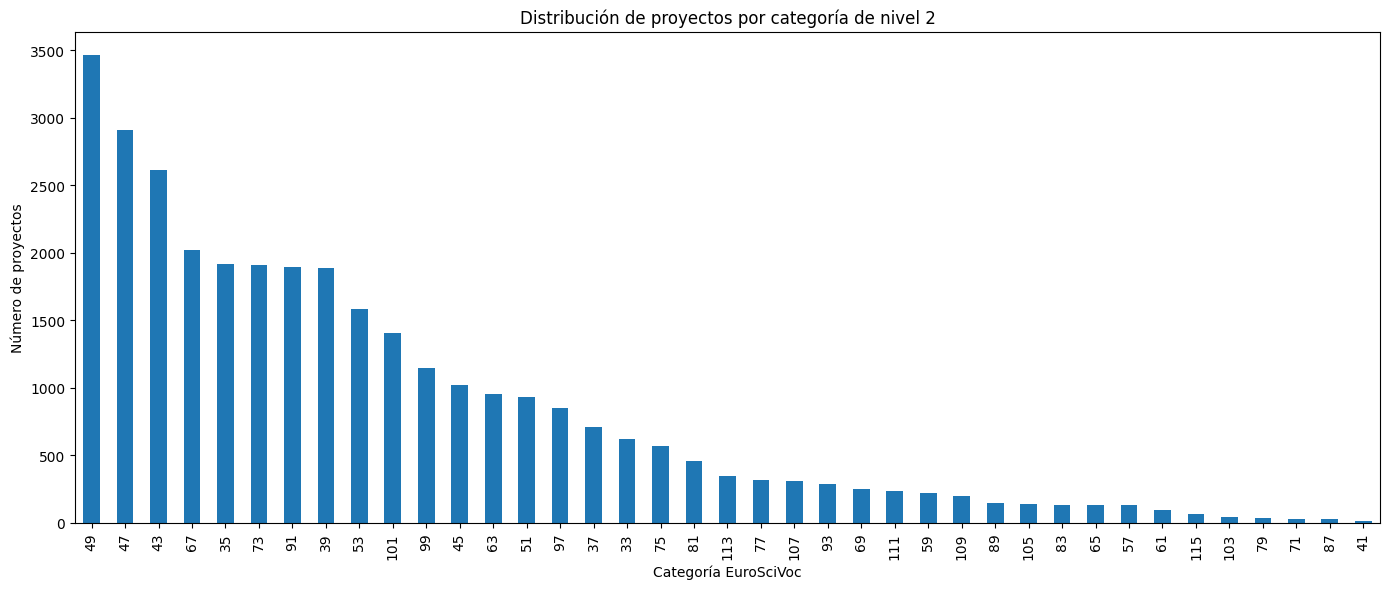

In [18]:
# Contamos proyectos por categoría
distribucion = df['label_nivel2'].value_counts().sort_values(ascending=False)

# Representamos la distribución
plt.figure(figsize=(14, 6))

distribucion.plot(kind='bar')

plt.title('Distribución de proyectos por categoría de nivel 2')
plt.xlabel('Categoría EuroSciVoc')
plt.ylabel('Número de proyectos')

plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(FIGURAS / "distribucion_clases.png", dpi=150, bbox_inches="tight")
plt.show()

La distribución permite comprobar el desbalance entre categorías.
Completar la discusión con las cifras de esta ejecución y explicar por
qué se usa macro-F1 además de accuracy.


La distribución de los proyectos entre las 39 categorías científicas de nivel 2 muestra un claro desequilibrio entre clases.

Las categorías más frecuentes son Basic medicine (3.464 proyectos), Physical sciences (2.912 proyectos) y Computer and information sciences (2.613 proyectos). En cambio, otras categorías cuentan con un número muy reducido de ejemplos.

Este desequilibrio puede afectar al entrenamiento de los clasificadores, ya que los modelos pueden aprender a predecir mejor las categorías mayoritarias y presentar dificultades para identificar las minoritarias.

Por este motivo, se utilizan dos métricas de evaluación:

- **Accuracy:** mide la proporción total de predicciones correctas, pero puede ofrecer resultados elevados cuando el modelo favorece las clases mayoritarias.

- **Macro-F1:** calcula el F1 de cada categoría y obtiene su media sin ponderar por el número de proyectos, dando la misma importancia a las clases mayoritarias y minoritarias.

Por tanto, macro-F1 se utiliza como métrica principal para comparar los modelos, mientras que accuracy se emplea como medida complementaria del rendimiento global.

### **2.2. Clasificador de referencia (baseline)**

In [19]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(df_train[["projectID"]], df_train["label_nivel2"])
pred_val = baseline.predict(df_val[["projectID"]])
clases = sorted(df_train["label_nivel2"].unique())
metricas_baseline = evaluar(df_val["label_nivel2"], pred_val, clases=clases)
display(pd.DataFrame([metricas_baseline]))
guardar_metricas(
    "baseline_nivel2", "ninguna", "clase_mayoritaria",
    2, "val", metricas_baseline,
)


,accuracy,macro_f1
0,0.108297,0.005011


,experimento,representacion,modelo,nivel,conjunto,accuracy,macro_f1
0,baseline_nivel2,ninguna,clase_mayoritaria,2,val,0.108297,0.005011


Completar la explicación con las métricas anteriores. El test se evalúa
cuando estén cerradas las decisiones de modelado.


El modelo se ha entrenado con los 19.189 proyectos de entrenamiento y se ha evaluado sobre los 9.594 proyectos de validación, obteniendo los siguientes resultados:

Accuracy: 0,1083 (10,83 %).

Macro-F1: 0,0050.

La accuracy indica que el modelo clasifica correctamente aproximadamente el 10,83 % de los proyectos de validación. Sin embargo, el valor de macro-F1 es extremadamente bajo porque el clasificador predice una única categoría y no consigue identificar las otras 38 categorías científicas de nivel 2.

Estos resultados evidencian el desequilibrio existente entre las clases y muestran que predecir siempre la categoría mayoritaria no es una estrategia adecuada para este problema.

Por tanto, el baseline servirá como punto de referencia para comparar el rendimiento de los modelos basados en TF-IDF, Word2Vec y BERT, que deberán superar estos valores para demostrar una mejora en la clasificación.

La evaluación sobre el conjunto de test se reserva para la fase final, una vez seleccionados los modelos y sus hiperparámetros mediante el conjunto de validación. De esta forma, se evita utilizar los datos de prueba durante la toma de decisiones y se obtiene una evaluación final independiente.

### **2.3. Análisis de la longitud de los resúmenes**

In [20]:
# Calcular el número de palabras de cada resumen
df['longitud_summary'] = df['summary'].str.split().str.len()

# Estadísticas descriptivas
display(df['longitud_summary'].describe().to_frame(name='Número de palabras'))

,Número de palabras
count,31982.000000
mean,265.344412
std,41.854020
min,1.000000
25%,257.000000
50%,276.000000
75%,289.000000
max,587.000000


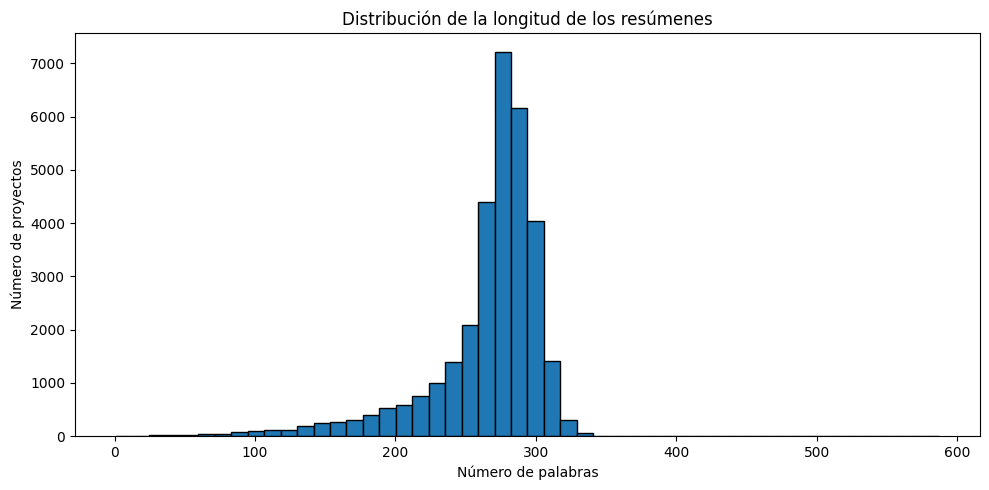

In [21]:
plt.figure(figsize=(10, 5))

plt.hist(df['longitud_summary'], bins=50, edgecolor='black')

plt.title('Distribución de la longitud de los resúmenes')
plt.xlabel('Número de palabras')
plt.ylabel('Número de proyectos')

plt.tight_layout()
plt.savefig(FIGURAS / "longitud_resumenes.png", dpi=150, bbox_inches="tight")
plt.show()

### **2.4. Distribución temporal de los proyectos**

In [22]:
# Extraer el año de inicio
df['startYear'] = df['startDate'].dt.year

# Contar proyectos por año
proyectos_anio = df['startYear'].value_counts().sort_index()

display(proyectos_anio.to_frame(name='Número de proyectos'))

,Número de proyectos
startYear,
2014.0,311
2015.0,4473
2016.0,4675
2017.0,4667
2018.0,4540
2019.0,4799
2020.0,3823
2021.0,3833
2022.0,848


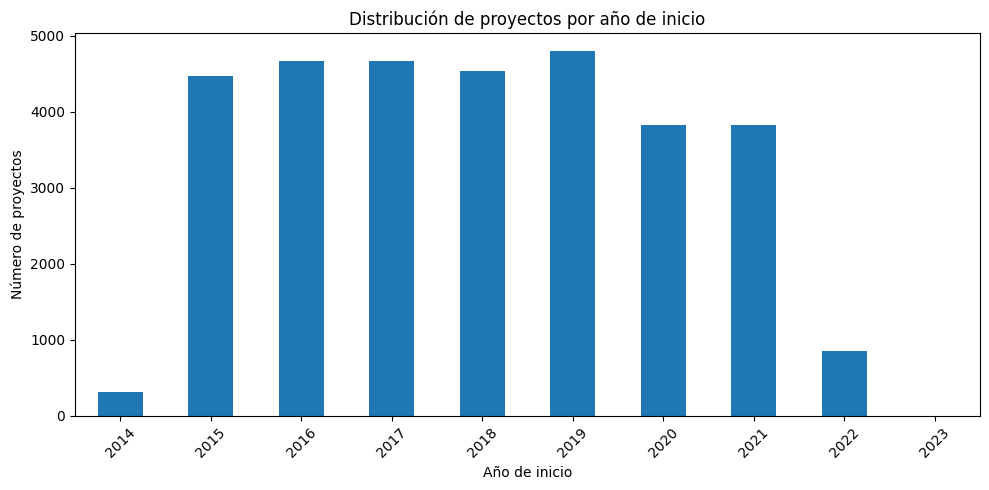

In [23]:
# Convertir los años a enteros
proyectos_anio.index = proyectos_anio.index.astype(int)

plt.figure(figsize=(10, 5))

proyectos_anio.plot(kind='bar')

plt.title('Distribución de proyectos por año de inicio')
plt.xlabel('Año de inicio')
plt.ylabel('Número de proyectos')

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURAS / "proyectos_por_anio.png", dpi=150, bbox_inches="tight")
plt.show()

### **2.5. Distribución geográfica de los proyectos**

In [24]:
# Contar proyectos por país coordinador
proyectos_pais = df['coordinatorCountry'].value_counts()

# Mostrar los 10 países con más proyectos
display(proyectos_pais.head(10).to_frame(name='Número de proyectos'))

,Número de proyectos
coordinatorCountry,
UK,5027
ES,3928
DE,3464
FR,3035
IT,2821
NL,2206
CH,1335
BE,1207
DK,1096


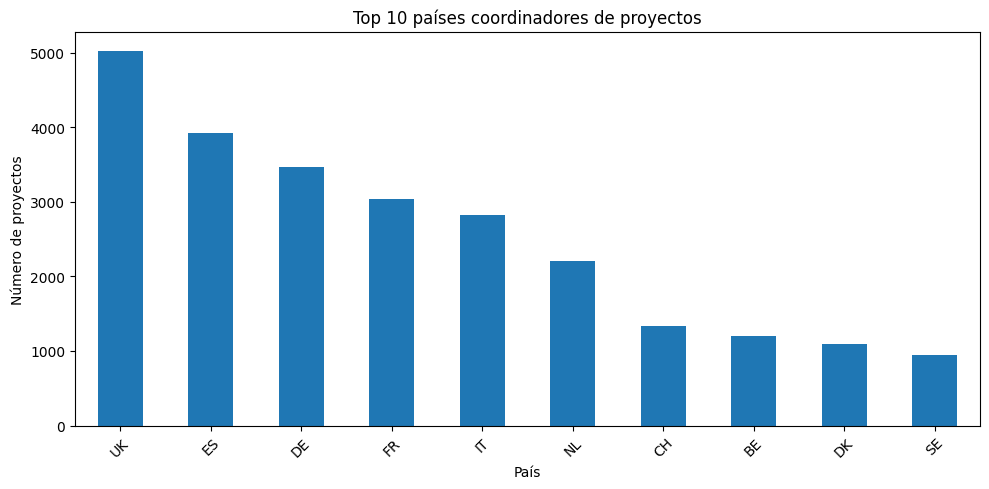

In [25]:
# Representamos los 10 países principales
plt.figure(figsize=(10, 5))

proyectos_pais.head(10).plot(kind='bar')

plt.title('Top 10 países coordinadores de proyectos')
plt.xlabel('País')
plt.ylabel('Número de proyectos')

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURAS / "proyectos_por_pais.png", dpi=150, bbox_inches="tight")
plt.show()

### **2.6. Análisis exploratorio del texto**

#### 2.6.1. Palabras más frecuentes

In [ ]:
# Creamos vectorizador eliminando stopwords en inglés
vectorizer = CountVectorizer(stop_words='english', max_features=20)

# Obtenemos frecuencias de palabras
X = vectorizer.fit_transform(df['summary'])

frecuencias = X.sum(axis=0).A1
palabras = vectorizer.get_feature_names_out()

# Crear DataFrame con las palabras más frecuentes
palabras_frecuentes = pd.DataFrame({'Palabra': palabras, 'Frecuencia': frecuencias}).sort_values(by='Frecuencia', ascending=False)

display(palabras_frecuentes)

,Palabra,Frecuencia
11,project,37361
9,new,28705
13,research,26700
1,based,19487
2,data,18300
7,high,16835
4,development,16105
5,energy,15027
18,use,14383
8,market,14345


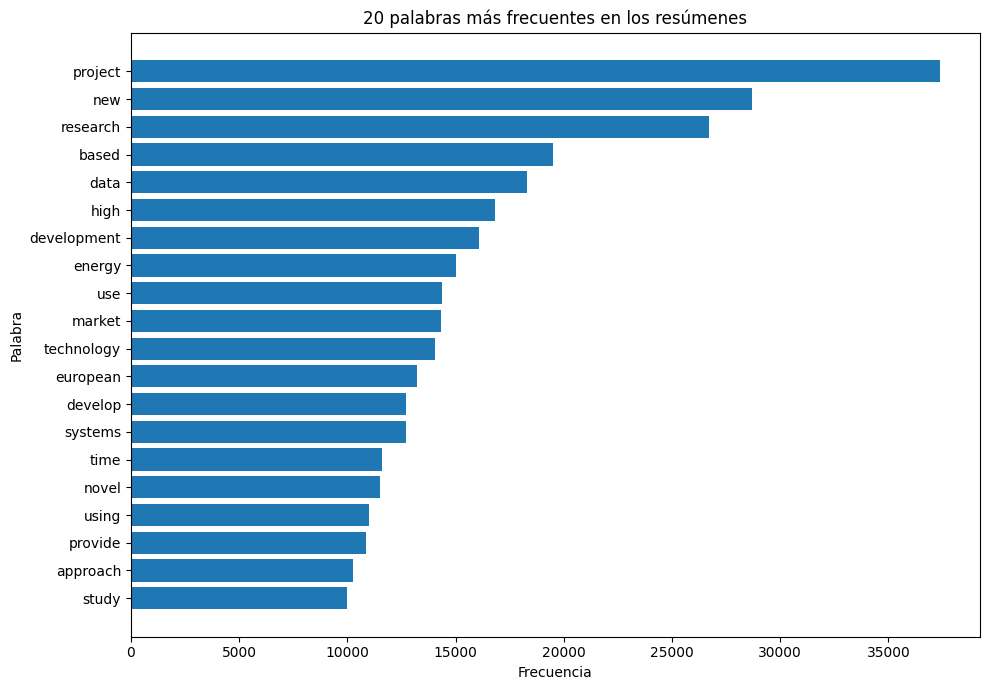

In [ ]:
plt.figure(figsize=(10, 7))

plt.barh(palabras_frecuentes['Palabra'], palabras_frecuentes['Frecuencia'])

plt.xlabel('Frecuencia')
plt.ylabel('Palabra')
plt.title('20 palabras más frecuentes en los resúmenes')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(FIGURAS / "palabras_frecuentes.png", dpi=150, bbox_inches="tight")
plt.show()

#### 2.6.2. Nube de palabras

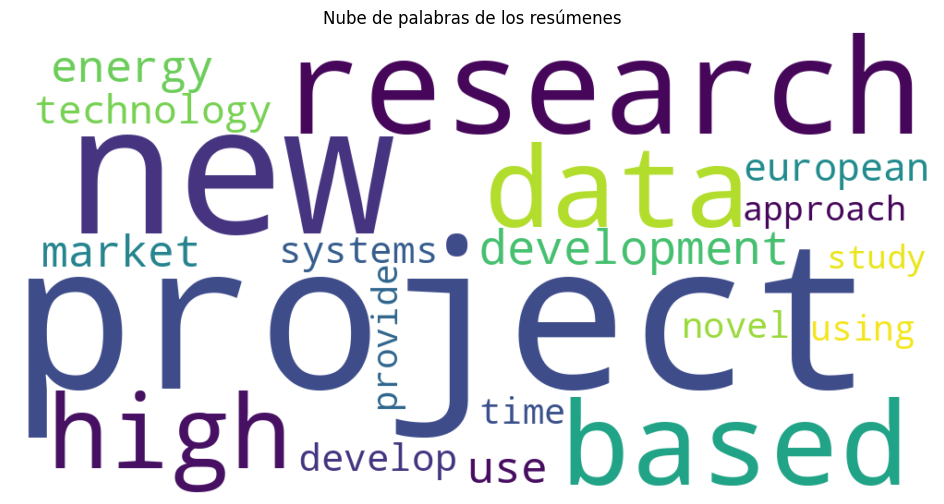

In [ ]:
# Crear diccionario de frecuencias
frecuencias_dict = dict(zip(palabras_frecuentes['Palabra'], palabras_frecuentes['Frecuencia']))

# Generar nube de palabras
wordcloud = WordCloud(width=1000, height=500, background_color='white').generate_from_frequencies(frecuencias_dict)

# Mostrar nube
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Nube de palabras de los resúmenes')
plt.savefig(FIGURAS / "nube_palabras.png", dpi=150, bbox_inches="tight")
plt.show()

#### 2.6.3. Identificación de categorías científicas

In [ ]:
# Crear diccionario de código a nombre de categoría
nombres_categorias = dict(zip(scivoc_clean['code'].astype(int), scivoc_clean['title']))

# Añadir el nombre de la categoría al DataFrame
df['categoria_nivel2'] = df['label_nivel2'].map(nombres_categorias)

# Comprobar el resultado
display(df[['projectID', 'label_nivel2', 'categoria_nivel2']].head(10))

,projectID,label_nivel2,categoria_nivel2
0,115843,35,basic medicine
1,115910,33,health sciences
2,635266,101,sociology
3,637488,35,basic medicine
4,639226,35,basic medicine
5,640254,53,chemical sciences
6,642935,67,environmental engineering
7,643002,73,"electrical engineering, electronic engineering..."
8,643937,47,computer and information sciences
9,645198,77,civil engineering


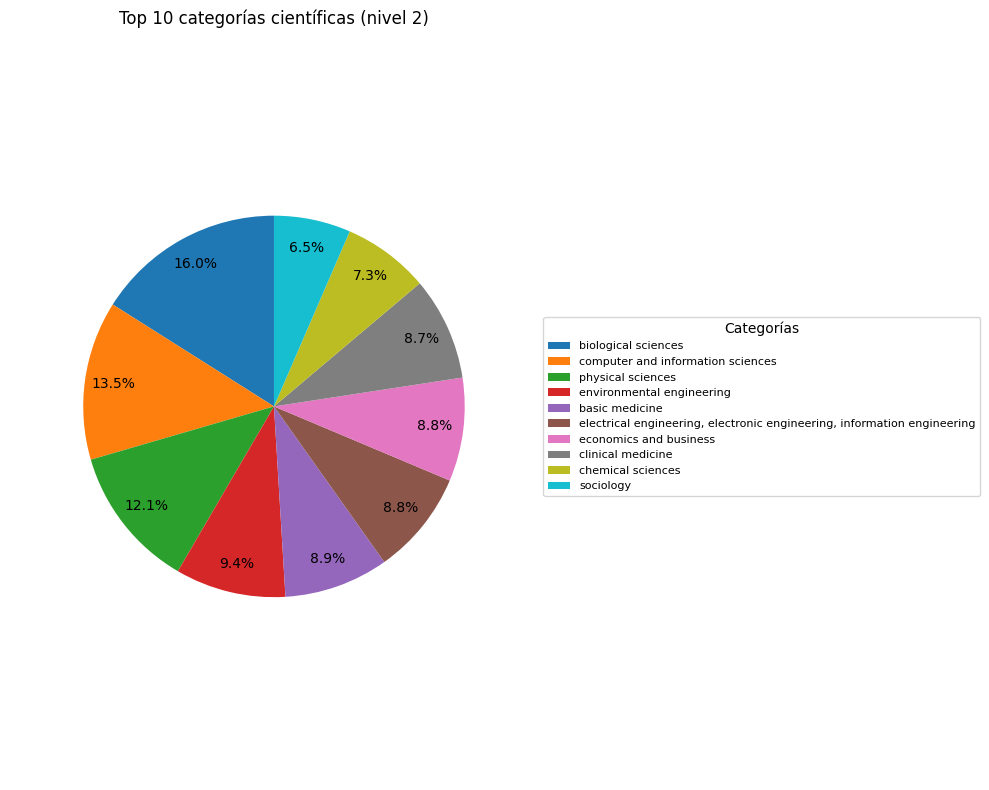

In [ ]:
# Contar proyectos por categoría
conteo = df['categoria_nivel2'].value_counts().head(10)

# Crear gráfico circular
plt.figure(figsize=(10, 8))

plt.pie(conteo, labels=None, autopct='%1.1f%%', startangle=90, pctdistance=0.85)
plt.title('Top 10 categorías científicas (nivel 2)')
plt.legend(conteo.index, title='Categorías', loc='center left', bbox_to_anchor=(1, 0.5), fontsize=8)
plt.axis('equal')
plt.tight_layout()
plt.savefig(FIGURAS / "top10categoriasNivel2.png", dpi=150, bbox_inches="tight")
plt.show()

#### 2.6.4. Ejemplos de proyectos por categorías

In [ ]:
# Seleccionamos las 5 categorías más frecuentes
categorias_top5 = df['label_nivel2'].value_counts().head(5).index

# Obtenemos 2 ejemplos de cada categoría
ejemplos = (df[df['label_nivel2'].isin(categorias_top5)].groupby('label_nivel2', group_keys=False).sample(n=2, random_state=42))

# Mostramos los ejemplos
display(ejemplos[['projectID', 'categoria_nivel2', 'title', 'summary']])

,projectID,categoria_nivel2,title,summary
20562,710938,basic medicine,A breakthrough in Renal Cell Carcinoma: Person...,"In oncology today, only 10 to 15% of patients ..."
1696,884163,basic medicine,"Structured, not stirred: experimental evolutio...",Given the looming antibiotic resistance crisis...
29578,704459,physical sciences,Hydrogen bonds in diblock copolymer/ homopolym...,HYBOCOMIX is focused on a combined theoretical...
23230,751164,physical sciences,Geological constraints on the crustal structur...,The internal structure of Mars provides valuab...
21105,861917,computer and information sciences,Safe Food for Infants in the EU and China,SAFFI targets food for EU’s 15 million and Chi...
23702,780751,computer and information sciences,Big Data to Enable Global Disruption of the Gr...,Big data is becoming a hype that is going to c...
11765,682810,biological sciences,Integrating spatial and genetic information vi...,Digital imaging of tissue samples and genetic ...
12011,836937,biological sciences,Personality in Community Ecology Responses: In...,Consistent behavioural variation between indiv...
130,827245,environmental engineering,"This proposal is about PREFEapp, an innovative...",This proposal refers to the development of PRE...
26085,776714,environmental engineering,Activating Circular Services in the Electric a...,C-SERVEES aims to boost a resource-efficient c...


In [ ]:
# FIGURAS
print("Carpeta de gráficas:", FIGURAS)
print("\nGráficas guardadas:")

for archivo in sorted(os.listdir(FIGURAS)):
    print(archivo)

Carpeta de gráficas: /content/resultados/graficas

Gráficas guardadas:
distribucion_clases.png
longitud_resumenes.png
nube_palabras.png
palabras_frecuentes.png
proyectos_por_anio.png
proyectos_por_pais.png
top10categoriasNivel2.png


## TF-IDF

Se reutiliza el preprocesamiento del cuaderno original: lematización,
minúsculas, eliminación de stopwords y tokens no alfabéticos o cortos.
El vocabulario se aprende únicamente con train.


In [ ]:
import spacy

nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
documentos = {
    nombre: preprocesar_resumenes(parte["summary"], nlp=nlp)
    for nombre, parte in conjuntos.items()
}
print("Original:", df_train["summary"].iloc[0][:500])
print("Limpio:", documentos["train"][0][:500])


Original: Are financial markets informationally efficient? Are some economic agents more informed than others? What is the impact of such heterogeneity on asset prices? These questions, of great economic significance, have permeated academic and business circles over the last few decades. Despite significant progress on the theoretical and empirical fronts relatively little is known about how information is endogenously acquired and processed in markets by agents with differential access to information an
Limpio: financial market informationally efficient economic agent informed impact heterogeneity asset price question great economic significance permeate academic business circle decade despite significant progress theoretical empirical front relatively little know information endogenously acquire process market agent differential access information face heterogeneous opportunity novel setting endogenous information acquisition non trivial heterogeneity project goal lay micro foundati

In [ ]:
tfidf, matrices_tfidf = crear_tfidf(documentos)
for nombre, matriz in matrices_tfidf.items():
    print(nombre, matriz.shape)
ruta = guardar_representacion("tfidf", matrices_tfidf, conjuntos)
print("Vectores guardados en:", ruta)


train (19189, 10000)
val (9594, 10000)
test (3199, 10000)
Vectores guardados en: /content/datos/cache/tfidf.joblib


## Word2Vec

Se conserva la media de los vectores de palabras conocida del cuaderno inicial.
El entrenamiento utiliza solo train. Se omiten palabras desconocidas y se
asigna un vector de ceros si no queda ninguna palabra utilizable.
Se usa un trabajador y semilla 42 para facilitar la repetición.


In [ ]:
%pip install gensim
modelo_w2v, matrices_w2v, resumen_oov = crear_word2vec(documentos)
for nombre, matriz in matrices_w2v.items():
    print(nombre, matriz.shape)
display(resumen_oov)
resumen_oov.to_csv(RESULTADOS / "word2vec_oov.csv", index=False)
ruta = guardar_representacion("word2vec", matrices_w2v, conjuntos)
print("Vectores guardados en:", ruta)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 30.9 MB/s  0:00:01
train (19189, 300)
val (9594, 300)
test (3199, 300)


,conjunto,tokens,tokens_oov,porcentaje_oov,documentos_sin_vector
0,train,2998584,30423,1.014579,0
1,val,1503614,41061,2.730821,1
2,test,499412,13964,2.796088,0


Vectores guardados en: /content/datos/cache/word2vec.joblib


In [ ]:
# Descargar archivos
files.download("/content/datos/cache/tfidf.joblib")
files.download("/content/datos/cache/word2vec.joblib")
files.download("/content/resultados/word2vec_oov.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Izan puede cargar los vectores desde su cuaderno. Si cambia el preprocesamiento
o algún parámetro de las representaciones, regenerar las cachés.


In [34]:
# Versiones utilizadas
print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("gensim:", gensim.__version__)
print("spaCy:", spacy.__version__)
print("pandas:", pandas.__version__)
print("NumPy:", numpy.__version__)

Python: 3.13.18
scikit-learn: 1.6.1
gensim: 4.4.0
spaCy: 3.8.18
pandas: 2.2.3
NumPy: 2.4.6


Parámetros definitivos:

- **TF-IDF**: 10.000 características, min_df=5, max_df=0.90, n-gramas (1,2).
- **Word2Vec**: 300 dimensiones, ventana 5, min_count=2, 10 épocas y seed=42.